# LARRY: genuine RNA velocity and PairScorer across culture time

## Biological idea and study design

The [LARRY study](https://doi.org/10.1126/science.aaw3381) follows hematopoietic cells through differentiation while retaining clonal barcodes. Here the practical question is whether early and later undifferentiated compartments differ in their inferred association with monocytic and neutrophil outcomes when the transition graph is estimated from **genuine spliced/unspliced molecules**.

We use the [Pyro-Velocity count deposit](https://doi.org/10.6084/m9.figshare.20780344.v1), whose authors report dropEst/velocyto processing of the original inDrop data. The public file is H5AD; we export its actual raw splicing layers to a verified loom and read them back. This is a lossless storage-format conversion, not reconstruction of velocity counts from gene expression.

We restrict the comparison to the same starting population, Lin−Kit+Sca1+, at day 2 and day 4. A documented cap per source-state/time stratum keeps this teaching workflow practical; full eligible composition is reported before sampling. **Culture time is not a treatment contrast.** The workflow does not interpret sequencing libraries, culture labels or clone barcodes as independent treatment replicates. Clone information is not used to build the velocity model or the supervised score, and this notebook does not claim held-out clonal predictive validation.

## Environment and reproducible settings

In [1]:
from pathlib import Path
import sys

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

In [2]:
from pathlib import Path
import sys
import json
import importlib.metadata as metadata

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import matplotlib.pyplot as plt
from IPython.display import display
import scCS
from benchmarks.validation.velocity_inputs import audit_counts, write_verified_loom

SEED = 19
DATA = PROJECT / "data" / "validation"
OUTPUT_DIR = PROJECT / "tutorial_outputs" / "larry_pair_velocity"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for package in ["scCS-py", "scanpy", "scvelo", "anndata"]:
    print(package, metadata.version(package))
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (7, 4)})

scCS-py 1.0.1.dev0
scanpy 1.12.6
scvelo 0.3.4
anndata 0.13.4


## 1. Load and audit genuine splicing counts

The original 1.53 GB count object is downloaded once and checked against the source MD5. The loader reads only the selected sparse layers; the expression-only CoSpar object and its chronological neighbor graph are not inputs to this analysis. The selected gene screen retains prespecified markers. Set `max_per_stratum=None` to retain all eligible cells, recognizing that this changes the graph and requires a new fit. Counts after stratified sampling must not be interpreted as biological abundance.

In [3]:
from benchmarks.validation.velocity_inputs import load_larry_counts

raw, composition, manifest = load_larry_counts(DATA, max_per_stratum=600, n_genes=2000, seed=SEED)
print(json.dumps(manifest, indent=2))
display(composition)
composition.to_csv(OUTPUT_DIR / "full_eligible_composition.csv")
display(audit_counts(raw))
raw.obs["clusters"] = raw.obs.source_state.map(
    {"Undifferentiated": "Root", "Monocyte": "Monocytic", "Neutrophil": "Neutrophil"}
).fillna("Outside")
display(pd.crosstab(raw.obs.source_state, raw.obs.condition))
(OUTPUT_DIR / "count_provenance.json").write_text(json.dumps(manifest, indent=2))

{
  "source": "https://ndownloader.figshare.com/files/37028569",
  "source_md5": "d618305c0ee0e41570b1147e63df332a",
  "starting_population": "Lin-Kit+Sca1+",
  "days": [
    2,
    4
  ],
  "max_per_state_time": 600,
  "requested_genes": 2000,
  "seed": 19,
  "eligible_cells": 8930,
  "loaded_cells": 2083,
  "clone_information_used_for_model": false
}
Out[0]: 354


time_info,2.0,4.0
state_info,,
Baso,9,172
Ccr7_DC,7,2
Eos,0,4
Erythroid,3,0
Lymphoid,14,86
Mast,2,55
Meg,1,18
Monocyte,1,386
Neutrophil,2,120


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,2083,2002,1433402.0,906941
1,unspliced,2083,2002,154804.0,138527


condition,day2,day4
source_state,,
Baso,9,172
Ccr7_DC,7,2
Eos,0,4
Erythroid,3,0
Lymphoid,14,86
Mast,2,55
Meg,1,18
Monocyte,1,386
Neutrophil,2,120


## 2. Read the analysis loom and verify exact count identity

For a uniform loom-based workflow we export the selected **measured** counts, then verify that cell IDs, gene IDs and both layers survive the round trip exactly. The output loom is an analysis subset, not a new raw-read quantification. Existing mismatched count files raise an error rather than silently substituting different input. The generated file is local data and is not bundled into the package.

In [4]:
LOOM_PATH = DATA / "larry_LSK_day2_day4_cap600_g2000_seed19.loom"
write_verified_loom(raw, LOOM_PATH)
adata = ad.read_loom(LOOM_PATH, obs_names="CellID", var_names="Gene", sparse=True)
display(audit_counts(adata))
print("Verified analysis loom:", LOOM_PATH)
del raw

Verified analysis loom: /workspace/scratch/1a48413c8396/work/scCS-1.0.1/data/validation/larry_LSK_day2_day4_cap600_g2000_seed19.loom


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,2083,2002,1433402.0,906941
1,unspliced,2083,2002,154804.0,138527


## 3. Fit RNA velocity in expression space

The velocity estimator sees the measured spliced/unspliced layers and the native expression-neighbor graph. It never sees the scCS star coordinates. This tutorial uses a deterministic steady-state scVelo fit as an explicit baseline; it does not claim to reproduce a published dynamical or Bayesian model. The model choice, count filtering, neighborhood and gene screen are assumptions to inspect before interpreting fate scores. A matching UMAP is recomputed for visualization only.

In [5]:
# Processing uses measured spliced/unspliced molecules, before any scCS display.
scv.pp.filter_genes(adata, min_shared_counts=10)
scv.pp.normalize_per_cell(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=30, random_state=SEED)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
scv.pp.moments(adata, n_neighbors=None, n_pcs=None)
scv.tl.velocity(adata, mode="deterministic")
scv.tl.velocity_graph(adata, n_jobs=1, show_progress_bar=False)
scv.tl.velocity_confidence(adata)
transition = scCS.get_scvelo_transition_matrix(adata)
adata.obsp["T_velocity"] = transition
print("Fitted velocity genes:", int(adata.var.velocity_genes.sum()))
display(
    adata.obs.groupby("condition", observed=True)[["velocity_length", "velocity_confidence"]].agg(
        ["median", "mean"]
    )
)
assert transition.shape == (adata.n_obs, adata.n_obs)
assert np.isfinite(transition.data).all()

Filtered out 298 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/9 cores)
    finished (0:00:00) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)
--> added 'velocity_confidence_transition' (adata.obs)
Fitted velocity genes: 233


velocity_length           velocity_confidence         
                   median      mean              median     mean
condition                                                       
day2                 0.80  0.825759            0.361308  0.37077
day4                 0.91  0.932562            0.459196  0.45696

## 4. Inspect the native field and phase portraits

Arrows are estimated from the fitted RNA-velocity model. Smoothness in a stream plot and agreement among neighbors are diagnostics, not independent evidence of correct cell fate. The phase portraits use the two highest-R-squared velocity genes; they are selected for fit inspection, not because their arrows support a desired treatment narrative. The displayed source annotations and sampled conditions let you assess overlap and gross inconsistencies.

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
Phase portraits selected by velocity fit R-squared: [np.str_('Ngp'), np.str_('Tph1')]


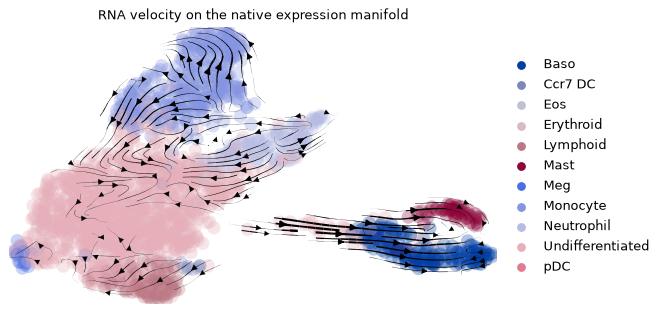

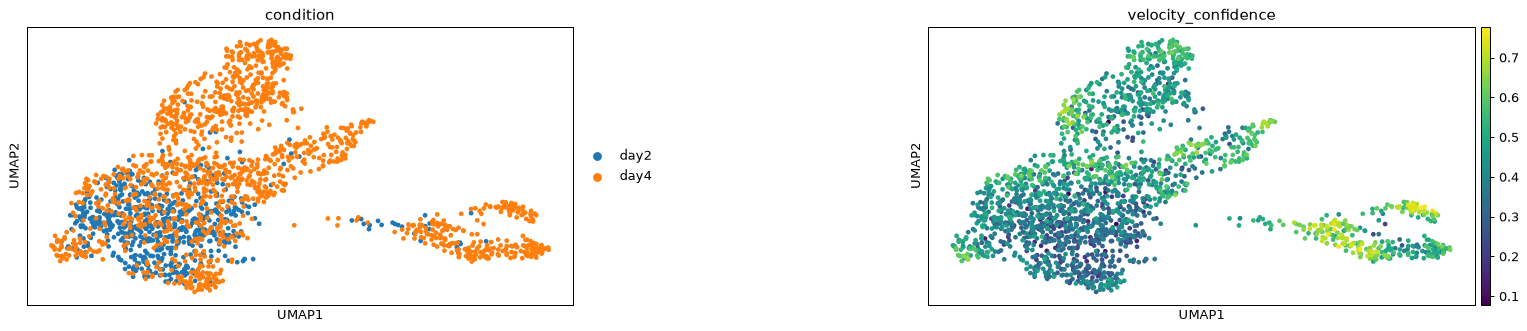

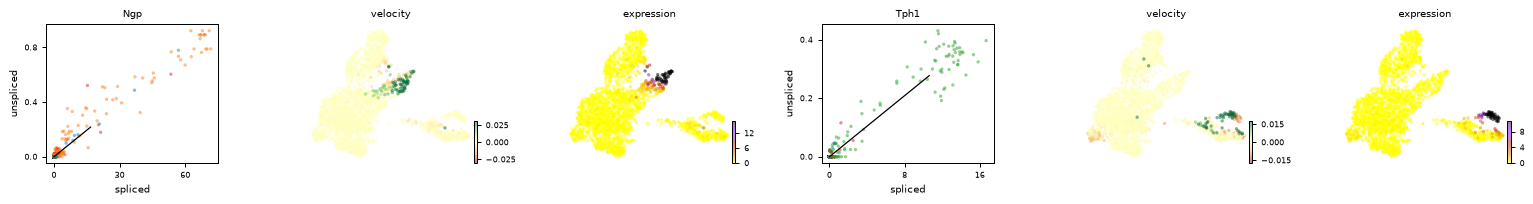

In [6]:
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="source_state",
    legend_loc="right margin",
    title="RNA velocity on the native expression manifold",
    show=False,
)
plt.show()
sc.pl.umap(adata, color=["condition", "velocity_confidence"], wspace=0.5, show=False)
plt.show()
phase_genes = (
    adata.var.loc[adata.var.velocity_genes]
    .sort_values("velocity_r2", ascending=False)
    .head(2)
    .index.tolist()
)
print("Phase portraits selected by velocity fit R-squared:", phase_genes)
if phase_genes:
    scv.pl.velocity(adata, var_names=phase_genes, ncols=2, show=False)
    plt.show()

## 5. Define the supervised question and velocity pseudotime

Undifferentiated cells form the root; monocytes and neutrophils are the selected outcomes. Other annotated states remain in the native graph as unselected context. Velocity pseudotime is rooted in the early undifferentiated population and supplies a continuous ordering. Because it is computed from the same velocity graph, it is not independent chronological evidence. Actual day labels are retained separately and never used to force forward transition edges.

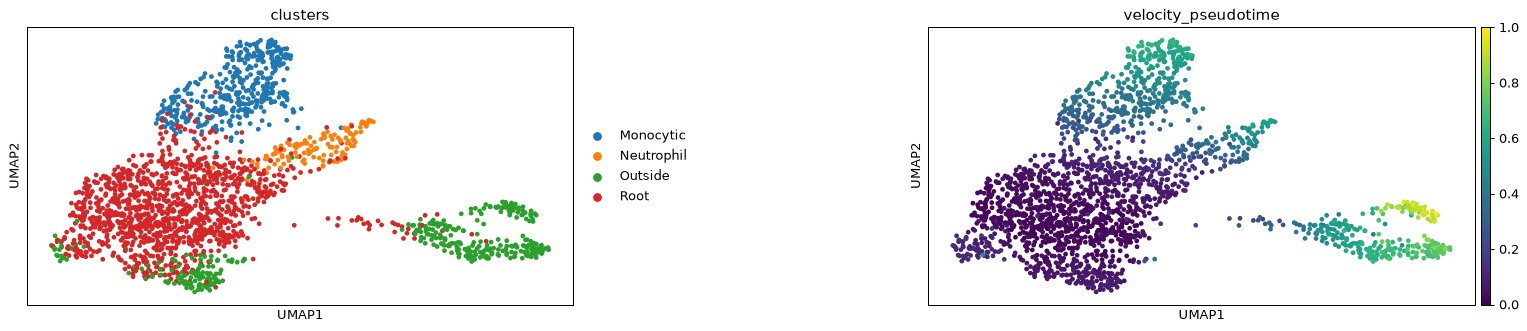

In [7]:
ROOT_LABEL = "Root"
FATES = ["Monocytic", "Neutrophil"]
REPLICATE_KEY = None
MARKER_GENES = ["Kit", "Lyz2"]
adata.obs["clusters"] = pd.Categorical(adata.obs.clusters)
adata.obs["early_root_hint"] = (
    adata.obs.clusters.eq("Root") & adata.obs.condition.eq("day2")
).astype(float)
scv.tl.velocity_pseudotime(adata, root_key="early_root_hint")
ORDERING_KEY = "velocity_pseudotime"
if not np.isfinite(adata.obs[ORDERING_KEY]).all():
    raise ValueError("Velocity pseudotime is undefined for some cells; inspect graph connectivity.")
sc.pl.umap(adata, color=["clusters", ORDERING_KEY], wspace=0.5, show=False)
plt.show()

## 6. Preflight, shared geometry and PairScorer

The pooled fit uses one graph, ordering and anchor definition for both conditions. Background states remain in the native graph even though the supervised display contains the selected root and fates. `min_replicates=1` permits descriptive score summaries only; it does not authorize formal inference with one patient or missing independent-replicate metadata. The preflight replication errors are retained as such, while structural errors stop execution. Inspect the post-fit report for dead ends, unreachable outcomes and defined-affinity coverage.

In [8]:
pair = scCS.PairScorer(
    adata,
    root=ROOT_LABEL,
    branches=FATES,
    obs_key="clusters",
    condition_obs_key="condition",
    replicate_obs_key=REPLICATE_KEY,
    condition_order=["day0", "day2"] if REPLICATE_KEY == "patient" else ["day2", "day4"],
)
report = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
report.display()
expected_design_errors = {f"condition_{condition}_replicates" for condition in pair.conditions}
unexpected = [d for d in report.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Structural preflight failure: " + "; ".join(d.message for d in unexpected))
if report.errors:
    print("Replication errors remain: descriptive scoring only; formal inference is unavailable.")
pair.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
FUTURE_OPTIONS = {"effective_horizon": 64, "anchor_quantile": 0.9, "min_anchor_cells": 3}
pair.fit(
    transition_matrix=transition,
    scoring_mode="future_fate",
    transition_scope="pooled",
    future_fate_options=FUTURE_OPTIONS,
    verbose=False,
)
results = pair.score_all_conditions(
    population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
)
postflight = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
postflight.display()
unexpected = [d for d in postflight.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Post-fit structural failure: " + "; ".join(d.message for d in unexpected))
postflight.to_frame().to_csv(OUTPUT_DIR / "preflight.csv", index=False)

,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1709.0
1,info,root_cells,Root population contains 1200 cells.,1200.0
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 387 cells.,387.0
3,info,terminal_Neutrophil,Terminal 'Neutrophil' contains 122 cells.,122.0
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.0
5,info,ordering_resolution,Root ordering has 1200 unique values across 12...,1.0
6,info,velocity_available,Velocity information is available.,NaN
7,info,condition_day2_cells,Condition 'day2' contains 639 cells.,639.0
8,info,condition_day4_cells,Condition 'day4' contains 1444 cells.,1444.0
9,warning,replicate_key_missing,No replicate key was supplied; formal conditio...,NaN


,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1709.000000
1,info,root_cells,Root population contains 1200 cells.,1200.000000
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 387 cells.,387.000000
3,info,terminal_Neutrophil,Terminal 'Neutrophil' contains 122 cells.,122.000000
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.000000
5,info,ordering_resolution,Root ordering has 1200 unique values across 12...,1.000000
6,info,velocity_available,Velocity information is available.,NaN
7,info,graph_dead_end_nonanchors,0 selected non-anchor cells have no positive o...,0.000000
8,info,root_unreachable_selected_anchors,0 root cells have no graph path to selected an...,0.000000
9,info,transition_coverage,"Root transition coverage median=1.000, q05=0.840.",0.840442


## 7. Read conditional affinity together with reach and coverage

CFA averages below use only explicitly defined root cells. DFR and UFP average across every root cell in the condition. These denominators answer different questions: DFR is a mean discounted probability, not the fraction of cells that will differentiate. No undefined CFA is replaced by zero. The table prints both the numerator and denominator for defined-affinity coverage, so a high conditional CFA cannot conceal a mostly unresolved population.

,condition,n_root_cells,n_defined_CFA,defined_fraction,DFR,UFP,SOF,CFA_Monocytic,CFA_Neutrophil
0,day2,600,600,1.0,0.007687,0.992313,-0.003354,0.788033,0.211967
1,day4,600,600,1.0,0.014625,0.985375,-0.048118,0.793473,0.206527


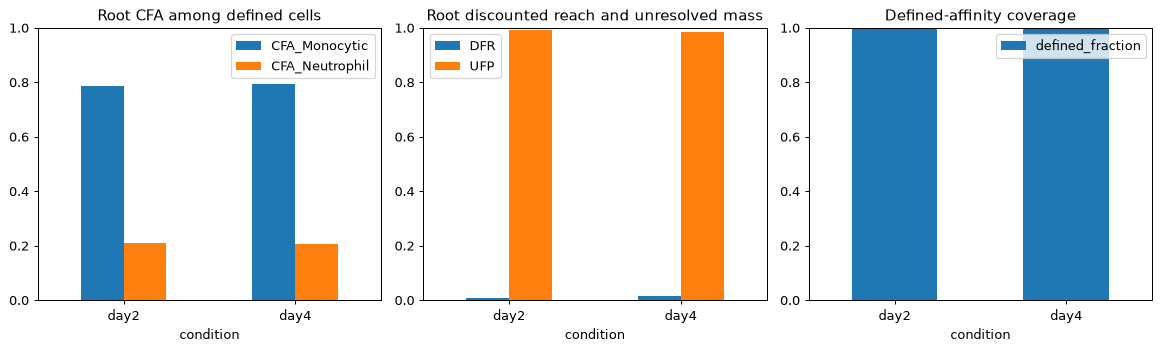

In [9]:
pooled = pair.result
rows = []
for condition, result in results.items():
    locations = pd.Index(pooled.cell_ids).get_indexer(result.cell_ids)
    assert (locations >= 0).all()
    defined = pooled.affinity_defined[locations]
    row = {
        "condition": condition,
        "n_root_cells": len(locations),
        "n_defined_CFA": int(defined.sum()),
        "defined_fraction": float(defined.mean()),
        "DFR": float(pooled.discounted_fate_reach[locations].mean()),
        "UFP": float(pooled.unresolved_probability[locations].mean()),
        "SOF": float(pooled.signed_progression[locations].mean()),
    }
    for j, fate in enumerate(pooled.fate_names):
        row["CFA_" + fate] = (
            float(pooled.conditional_fate_affinity[locations[defined], j].mean())
            if defined.any()
            else np.nan
        )
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUTPUT_DIR / "condition_summary.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
summary.set_index("condition")[["CFA_" + f for f in FATES]].plot.bar(ax=axes[0], ylim=(0, 1))
summary.set_index("condition")[["DFR", "UFP"]].plot.bar(ax=axes[1], ylim=(0, 1))
summary.set_index("condition")[["defined_fraction"]].plot.bar(ax=axes[2], ylim=(0, 1))
axes[0].set_title("Root CFA among defined cells")
axes[1].set_title("Root discounted reach and unresolved mass")
axes[2].set_title("Defined-affinity coverage")
for axis in axes:
    axis.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

## 8. Compare conditions on the same star

These are shared-geometry displays of the native-graph results. Refitting dynamics in the star would change the model and is not performed. Inspect population identity, the first fate's CFA, selected-fate reach, unresolved probability and Signed Ordering Flux (SOF). SOF describes movement relative to the chosen ordering; it is not an independent measurement of chronological maturation.

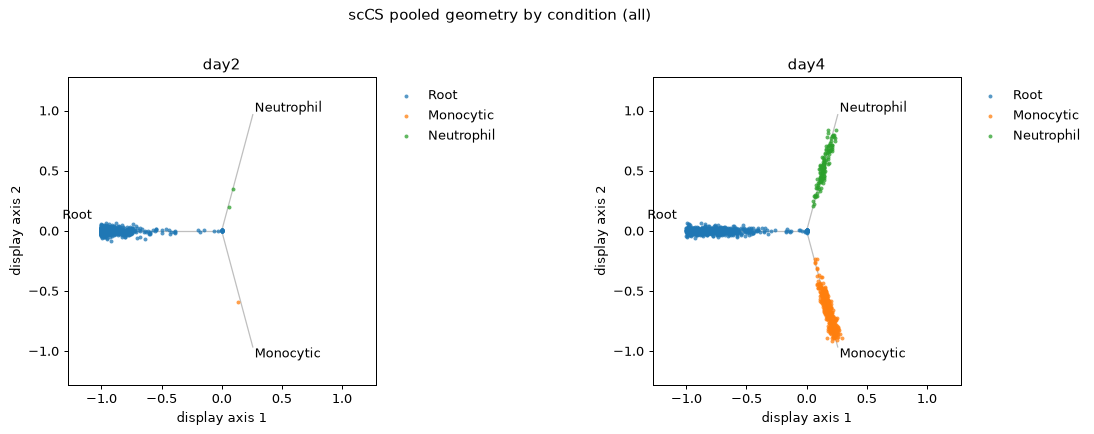

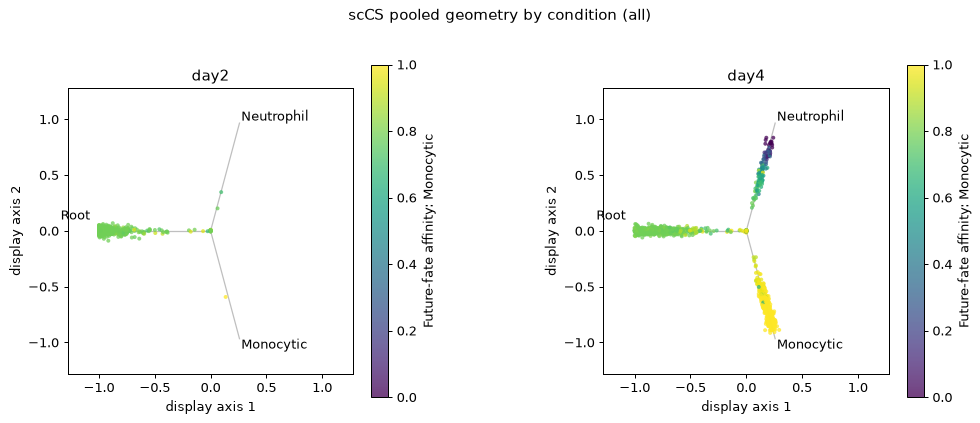

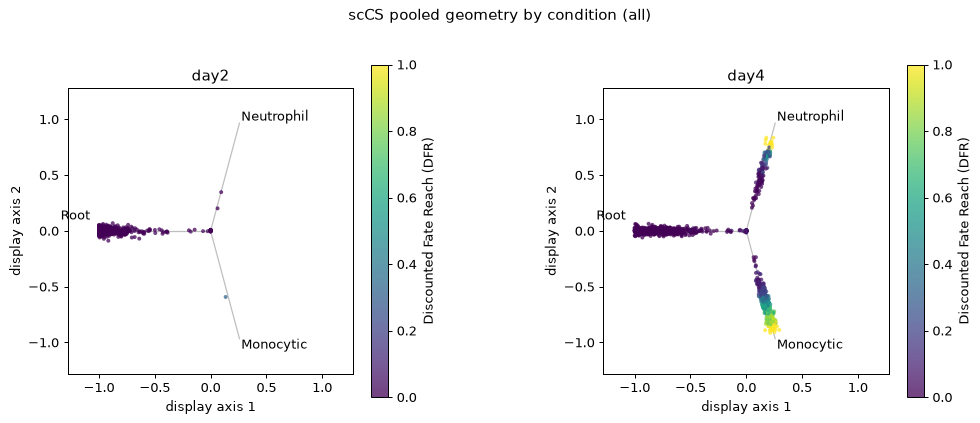

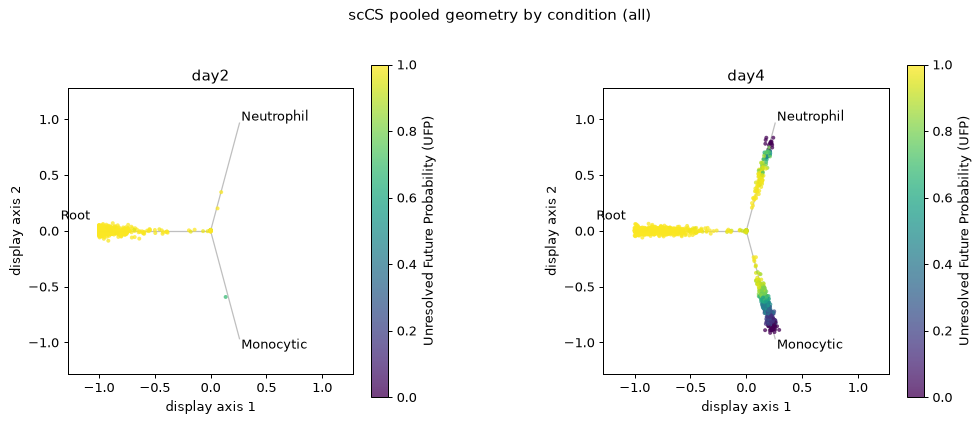

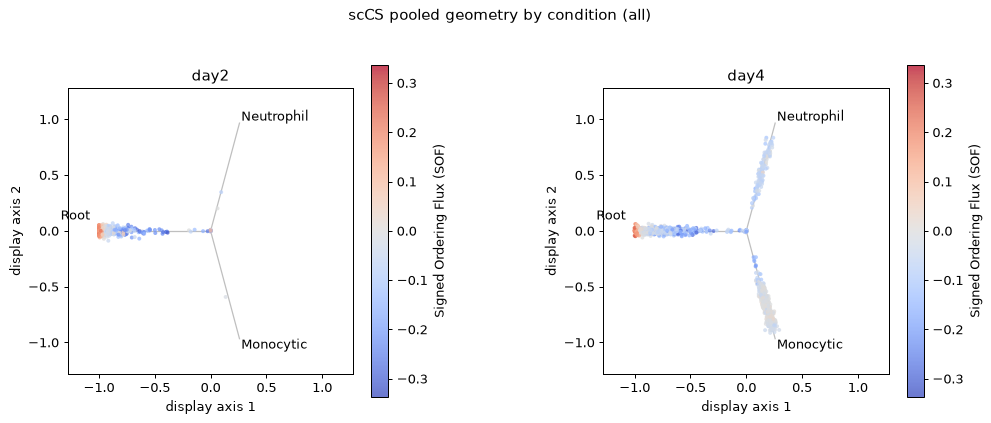

In [10]:
for color_by in [
    "population",
    "future_fate_affinity:" + FATES[0],
    "future_fate_reach",
    "unresolved_future_probability",
    "signed_progression",
]:
    figure = pair.plot_star_grid(
        results, color_by=color_by, population="all", ncols=2, figsize_per_panel=(6.4, 4.8)
    )
    if color_by == "population":
        figure.subplots_adjust(wspace=0.9)
    plt.show()

## 9. Inspect status, transition coverage and expression

Status and mean root graph-coverage plots help distinguish missing information from a conditional preference. The coverage bars have no replicate confidence intervals. Marker expression is shown from the normalized, log-transformed `X` matrix on a shared color scale. These panels are descriptive checks rather than differential-expression tests or proof that a root cell produced a particular descendant.

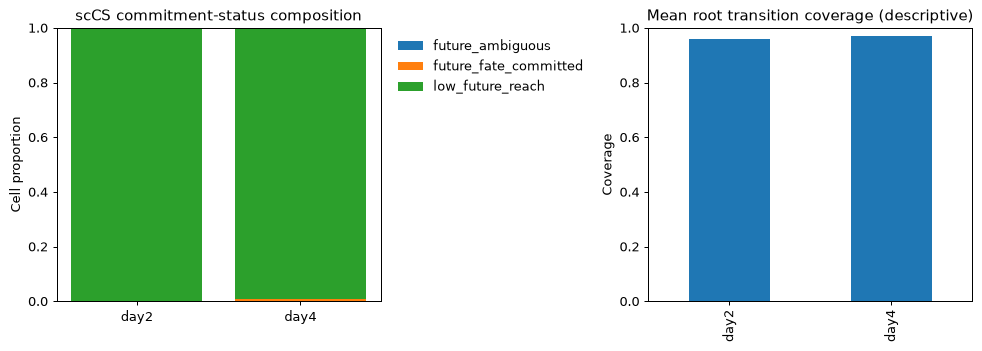

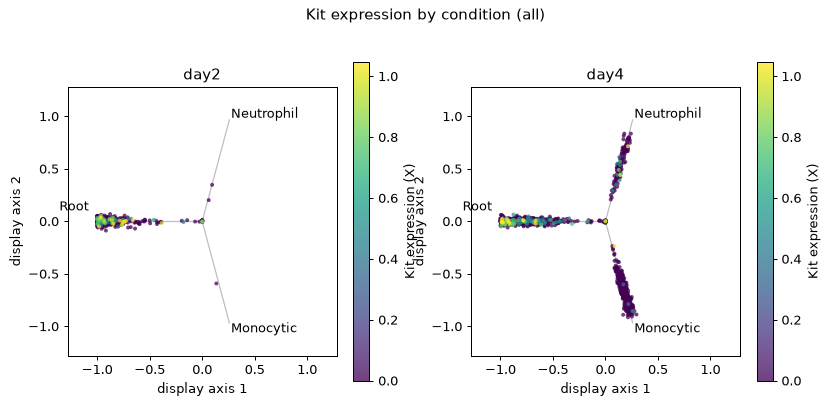

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pair.plot_status_composition(results, ax=axes[0])
coverage_means = pd.Series(
    {name: np.mean(value.transition_coverage) for name, value in results.items()}
)
coverage_means.plot.bar(ax=axes[1], ylim=(0, 1))
axes[1].set_title("Mean root transition coverage (descriptive)")
axes[1].set_ylabel("Coverage")
fig.tight_layout()
plt.show()
for gene in MARKER_GENES:
    if gene in adata.var_names:
        pair.plot_gene_expression_star_grid(
            gene, results, shared_scale=True, ncols=2, figsize_per_panel=(5.3, 4.6)
        )
        plt.show()

## 10. Sensitivity to borrowing between conditions

The pooled graph can borrow neighbors across conditions. Blocking cross-condition transitions tests a different graph assumption while retaining the same velocity fit and supervised outcome definition. It does not refit scVelo independently in each condition. Lower reach after blocking can result from lost graph connections; it is not automatically evidence for biological arrest.

In [12]:
scope_rows = []
for scope in ["pooled", "condition"]:
    sensitivity = scCS.PairScorer(
        adata,
        root=ROOT_LABEL,
        branches=FATES,
        obs_key="clusters",
        condition_obs_key="condition",
        replicate_obs_key=REPLICATE_KEY,
        condition_order=list(results),
    )
    sensitivity.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
    sensitivity.fit(
        transition_matrix=transition,
        scoring_mode="future_fate",
        transition_scope=scope,
        future_fate_options=FUTURE_OPTIONS,
        verbose=False,
    )
    condition_results = sensitivity.score_all_conditions(
        population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
    )
    for condition, result in condition_results.items():
        scope_rows.append(
            {
                "scope": scope,
                "condition": condition,
                "DFR": float(np.mean(result.commitment_strength)),
                "UFP": float(np.mean(result.unresolved_probability)),
                "defined_fraction": float(np.mean(result.affinity_defined)),
            }
        )
scope_summary = pd.DataFrame(scope_rows)
display(scope_summary)
scope_summary.to_csv(OUTPUT_DIR / "transition_scope_sensitivity.csv", index=False)

,scope,condition,DFR,UFP,defined_fraction
0,pooled,day2,0.007687,0.992313,1.0
1,pooled,day4,0.014625,0.985375,1.0
2,condition,day2,0.000000,1.000000,0.0
3,condition,day4,0.030967,0.969033,1.0


## 11. Respect the experimental unit

The source metadata are retained without inventing donors from cells, library batches, time points or clone barcodes. A formal PairScorer comparison is attempted below to show that the unsupported design is rejected. The appropriate output here is descriptive scores with explicit coverage. Independent biological replication, and an analysis that respects any pairing, would be required for population-level treatment inference.

In [13]:
# Requesting a formal test must fail rather than use cells as independent replicates.
try:
    pair.compare_conditions(results, metric="future_fate_reach", verbose=False)
except ValueError as error:
    print("Formal inference is unavailable for this design:", error)
    inference_refused = True
else:
    raise AssertionError("This descriptive design must not produce a treatment p-value.")

Formal inference is unavailable for this design: compare_conditions requires replicate_obs_key. Cell-level permutation is intentionally not used for formal inference.


## 12. Export and interpretation

The analysis object stores the actual splicing layers after normalization, fitted velocity vectors, native neighbor graph, UMAP, ordering and scCS scores. The source count files and checksums remain the reference for raw molecules. CSV exports record the condition summaries, graph-scope sensitivity and velocity diagnostics. Figures are retained in this executed notebook for Read the Docs.

In [14]:
pair.result.write_to_adata(adata)
adata.write_h5ad(OUTPUT_DIR / "pair_scorer_velocity_analysis.h5ad")
adata.obs[
    ["condition", "source_state", "velocity_length", "velocity_confidence", ORDERING_KEY]
].to_csv(OUTPUT_DIR / "velocity_and_ordering_qc.csv")
assert inference_refused
assert summary.n_root_cells.gt(0).all()
assert summary.defined_fraction.between(0, 1).all()
assert np.isfinite(adata.layers["velocity"]).all()
print(
    "Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to", OUTPUT_DIR
)

Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to /workspace/scratch/1a48413c8396/work/scCS-1.0.1/tutorial_outputs/larry_pair_velocity


## Reading the recorded result

With the recorded teaching-size sampling and pooled graph, all **600/600** selected root cells at each time point have defined CFA. Mean monocytic CFA is approximately **0.788** at day 2 and **0.793** at day 4. This small descriptive difference does not establish a changed fate decision.

Complete defined-affinity coverage coexists with low DFR: approximately **0.00769** and **0.01462**. Thus 98.5–99.2% of mean probability mass remains unresolved at the specified horizon. A defined conditional ratio alone does not imply a strongly supported or calibrated fate prediction.

With cross-condition edges blocked, day-2 DFR becomes zero and its CFA is undefined, while day-4 DFR is approximately 0.0310. The pooled day-2 readout therefore depends on cross-time graph connections and the pooled anchor definition. The blocked graph is a sensitivity analysis, not a superior fit or evidence of biological arrest. Mean SOF is negative at both time points relative to the chosen velocity-pseudotime ordering; inspect that disagreement rather than equating later sampling with positive inferred progression.

## What the result can support

These outputs describe differences between sampled culture time points under an RNA-velocity-derived graph. The transition field is inferred from splicing measurements; the observed day labels identify the comparison groups without forcing forward-time graph edges. Clonal outcomes are reserved for a separate validation task.

Inspect low reach, missing affinity and reverse arrows rather than interpreting every difference as developmental progress. A lineage-prediction benchmark would additionally require a locked split of clone outcomes, exclusion of held-out future information before model fitting, matched baselines and coverage reporting. This descriptive PairScorer tutorial does not perform that experiment or establish superiority over CellRank.